# Vigor da vegetação por cultura com Sentinel-2 e Google Earth Engine
Série mensal 2019–2026 de NDVI / NDRE / NDMI em talhões de 8 usos do solo (cacau, café, banana, coco, milho irrigado, eucalipto, pasto e IPF), cruzada com chuva (CHIRPS).

**Perguntas:** (1) como cada cultura se comporta ao longo do ano? (2) quando a vegetação saiu do normal? (3) qual cultura responde mais à chuva?

> Rode primeiro `src/anonymize.py` (gera `data/talhoes_anonimo.geojson`). A análise usa a geometria real (privada); só os resultados anonimizados são publicados.

In [12]:
# %pip install -q earthengine-api geemap pandas numpy matplotlib   # descomente no Colab
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd
import config as C, anonymize, gee_extract as G, analysis as A
C.OUT.mkdir(exist_ok=True); (C.OUT / "privado").mkdir(exist_ok=True)

## 1. Dados e anonimização

In [13]:
anonymize.anonimizar()                 # gera data/talhoes_anonimo.geojson
areas = A.carregar_areas()
areas.groupby("cultura").area_ha.agg(["count", "sum"]).round(0).sort_values("sum", ascending=False)

,count,sum
cultura,,
Pasto,4,791.0
Eucalipto,2,498.0
Cacau,5,264.0
Café,5,262.0
Banana,1,175.0
IPF,3,165.0
Milho (pivô),2,139.0
Coco,1,102.0


In [14]:
# Área nominal (escrita no nome do polígono) vs. área mapeada
A.area_nominal_vs_mapeada(areas)

,id,cultura,area_nominal_ha,area_ha,dif_ha,dif_pct
0,Cacau-01,Cacau,100.00,146.0,46.0,46.0
5,Milho-01,Milho (pivô),64.00,71.7,7.7,12.0
6,Milho-02,Milho (pivô),72.00,67.1,-4.9,-7.0
11,Café-02,Café,18.00,20.6,2.6,14.0
12,Café-03,Café,51.26,62.1,10.8,21.0
13,Café-04,Café,78.00,94.8,16.8,22.0
15,Coco-01,Coco,101.00,102.3,1.3,1.0
16,Banana-01,Banana,154.00,174.6,20.6,13.0


## 2. Extração no Earth Engine
Sentinel-2 SR Harmonizado + máscara de nuvem **Cloud Score+** (`cs_cdf ≥ 0.60`), composto mensal por mediana, média por talhão (10 m).

In [15]:
G.iniciar()                            # defina EE_PROJECT em src/config.py
fc = G.talhoes_fc()
cache = C.OUT / "privado" / "s2_mensal.csv"
if cache.exists():
    df = pd.read_csv(cache, parse_dates=["data"])
else:
    df = G.serie_s2(fc)
    df.to_csv(cache, index=False)
df.head()

,NDMI,NDRE,NDVI,ano,cultura,id,mes,n_cenas,data
0,0.458984,0.621636,0.840406,2019,Banana,Banana-01,1,7,2019-01-01
1,0.439332,0.598727,0.807000,2019,Banana,Banana-01,2,5,2019-02-01
2,0.452706,0.615006,0.834598,2019,Banana,Banana-01,3,6,2019-03-01
3,0.463267,0.636498,0.835699,2019,Banana,Banana-01,4,6,2019-04-01
4,0.457069,0.653870,0.844952,2019,Banana,Banana-01,5,7,2019-05-01


In [16]:
cache_c = C.OUT / "privado" / "clima_mensal.csv"
if cache_c.exists():
    clima = pd.read_csv(cache_c, parse_dates=["data"])
else:
    clima = G.clima_mensal(fc); clima.to_csv(cache_c, index=False)
clima.tail()

,chuva_mm,data,lst_c
88,19.299523,2026-05-01,22.155572
89,43.098829,2026-06-01,20.894732
90,23.419795,2026-07-01,20.905381
91,57.123727,2026-08-01,22.784555
92,NaN,2026-09-01,23.549780


In [17]:
# Dados publicáveis (sem coordenadas, só IDs anônimos)
df.drop(columns=["n_cenas"], errors="ignore").to_csv(C.OUT / "ndvi_ndre_ndmi_mensal.csv", index=False)
clima.to_csv(C.OUT / "clima_mensal.csv", index=False)
print("cenas válidas por mês (mediana):", df.groupby("data").n_cenas.first().median())

cenas válidas por mês (mediana): 6.0


## 3. Perfil sazonal por cultura

,min,max,amplitude,mes_pico
cultura,,,,
Pasto,0.409,0.668,0.258,mar
IPF,0.420,0.658,0.239,mar
Eucalipto,0.412,0.615,0.204,fev
Café,0.491,0.669,0.177,mai
Cacau,0.719,0.879,0.160,abr
Milho (pivô),0.358,0.507,0.149,dez
Coco,0.638,0.735,0.096,jul
Banana,0.768,0.860,0.092,jun


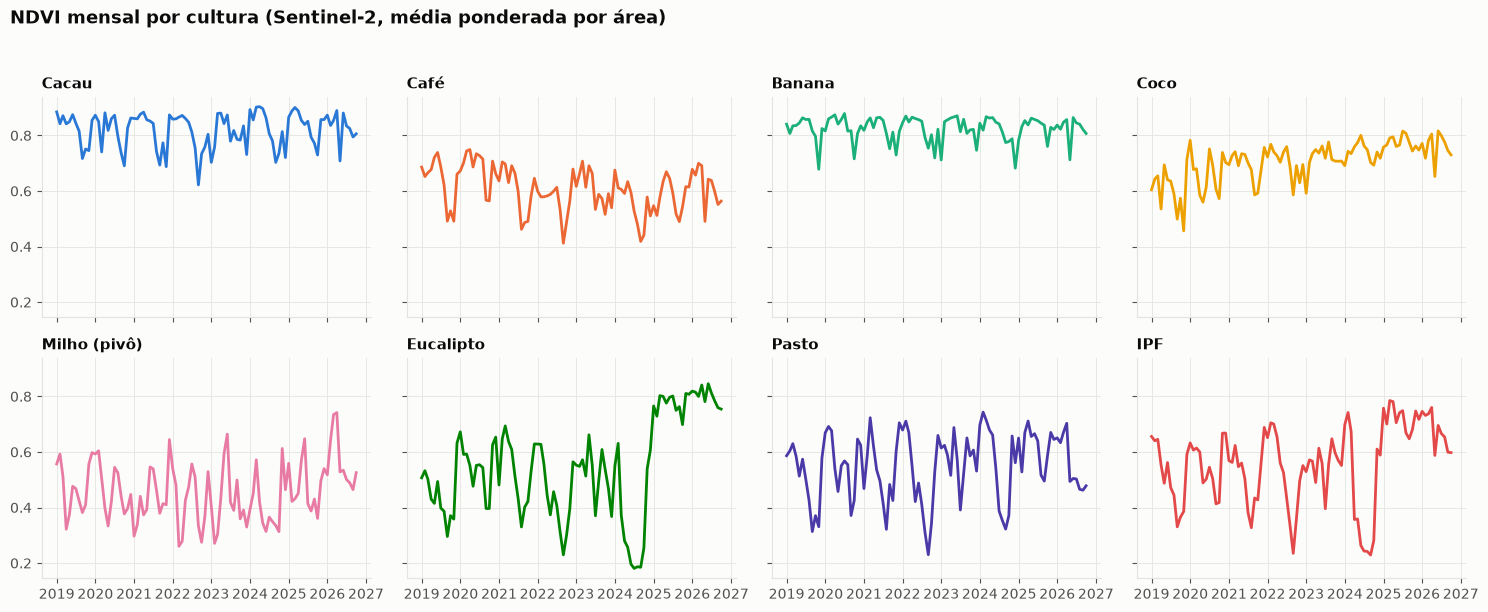

In [18]:
sc = A.serie_cultura(df, areas)
clim = A.climatologia(sc)
display(A.amplitude_sazonal(clim))
A.fig_curvas(sc, destino=C.OUT / "01_curvas_ndvi.png");

## 4. Anomalias: quando a vegetação fugiu do normal
z-score do NDVI mensal contra a climatologia 2019–2025.

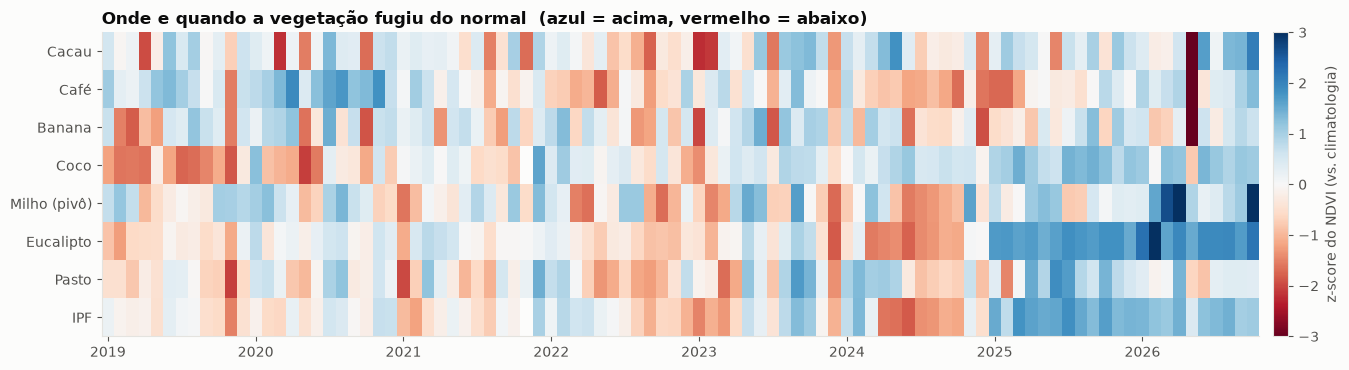

In [19]:
ac = A.anomalia_cultura(sc)
A.fig_anomalias(ac, destino=C.OUT / "02_anomalias.png");

## 5. Sensibilidade à chuva
Correlação entre o z-score do NDVI e o z-score da chuva, testando defasagens de 0 a 3 meses.

,cultura,lag_meses,r,n
0,Pasto,1,0.47,92
1,Café,1,0.37,92
2,Eucalipto,1,0.30,92
3,IPF,1,0.26,91
4,Milho (pivô),1,0.26,92
5,Cacau,3,0.19,90
6,Banana,3,0.09,90
7,Coco,3,0.02,89


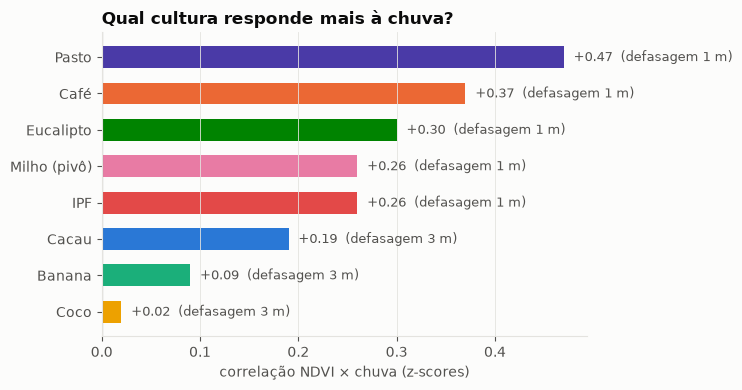

In [20]:
sens = A.sensibilidade_hidrica(ac, clima)
display(sens)
A.fig_sensibilidade(sens, destino=C.OUT / "03_sensibilidade_chuva.png");

## 6. Mapa esquemático (sem base cartográfica)

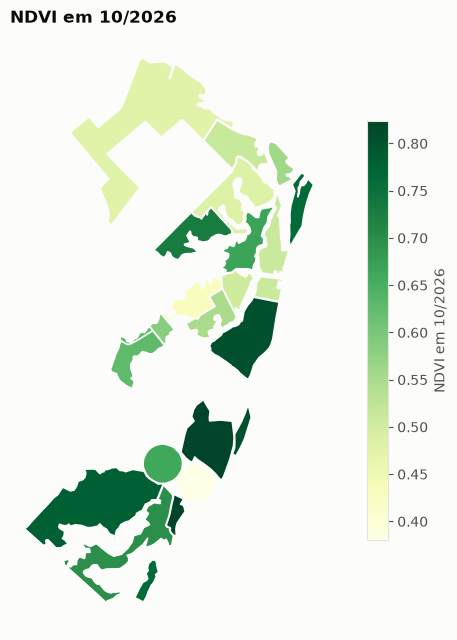

In [21]:
ult = df[df.data == df.data.max()].set_index("id").NDVI.to_dict()
A.fig_mapa_esquematico(C.GEOJSON_ANON, ult, f"NDVI em {df.data.max():%m/%Y}",
                       destino=C.OUT / "04_mapa_ndvi.png");

## 7. Mapa interativo com base de satélite (**só se tiver autorização**)

In [22]:
PUBLICAR_MAPA_REAL = False     # True só com autorização do proprietário
import geemap
m = geemap.Map(); m.add_basemap("SATELLITE")
comp = G.composto_mensal(fc.geometry().bounds(), 2026, 8).select("NDVI")
m.addLayer(comp.clip(fc), {"min": .2, "max": .9, "palette": ["#d73027", "#fee08b", "#1a9850"]}, "NDVI ago/2026")
m.addLayer(fc.style(color="white", fillColor="00000000", width=1), {}, "Talhões")
m.centerObject(fc, 12)
if PUBLICAR_MAPA_REAL:
    m.to_html(C.OUT / "mapa_interativo.html")
m

Map(center=[-19.438793473799997, -40.20172671712831], controls=(WidgetControl(options=['position', 'transparen…

## 8. Conclusões (preencha com os seus resultados)
- Cultura com maior amplitude sazonal: …
- Meses/anos com anomalia negativa mais forte: …
- Cultura mais sensível à chuva e defasagem: …
- Limitações: média por polígono inclui estradas e bordas; NDVI satura em dossel denso; sem validação de campo.